## A prototype model for identifying key mutations for FIPV/FECV switch

### 1. Minimum implementation of GWAS-like statistical test

In [1]:
# Arial fontがないためこちらで実行
import pandas as pd
import numpy as np
from Bio import SeqIO
from statsmodels.stats.multitest import multipletests
from scipy.stats import fisher_exact
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.font_manager import FontProperties, findfont

# 1. SVGのフォント設定（テキストとして保持する設定）
mpl.rcParams['svg.fonttype'] = 'none'

# 2. Arialフォントをシステムから検索して設定
try:
    # Arialを探し、パスを取得
    arial_path = findfont(FontProperties(family='Arial'))
    # FontPropertiesを生成
    arial_font = FontProperties(fname=arial_path)
    # matplotlibに適用
    plt.rcParams['font.family'] = arial_font.get_name()
    print(f"Arialフォントを適用しました: {arial_path}")
except Exception as e:
    print(f"Arialが見つかりません。デフォルトフォントを使用します: {e}")
    plt.rcParams['font.family'] = 'sans-serif'

Arialフォントを適用しました: /System/Library/Fonts/Supplemental/Arial.ttf


In [2]:
meta = pd.read_csv("FCoV1_full_ORF_meta_20260311.tsv", sep="\t")
meta

,Accession,biotype,Organism_Name,Isolate,Species,Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,Source
0,PQ416775.1,FIPV,Feline coronavirus,H30,Alphacoronavirus suis,29201,China: Shandong,China,Felis catus,liver,2023-11-05,2025-10-01,NCBI
1,PX315748.1,FIPV,Feline coronavirus,fip_37_liver,Alphacoronavirus suis,28497,United Kingdom,United Kingdom,Felis catus,liver,2011-10,2025-09-24,NCBI
2,PX315749.1,FIPV,Feline coronavirus,fip_68_liver,Alphacoronavirus suis,28550,United Kingdom,United Kingdom,Felis catus,liver,2013-01-11,2025-09-24,NCBI
3,PX315750.1,FIPV,Feline coronavirus,fip_68_mln,Alphacoronavirus suis,29246,United Kingdom,United Kingdom,Felis catus,lymph,2013-01-11,2025-09-24,NCBI
4,PX315751.1,FIPV,Feline coronavirus,fip_86_liver,Alphacoronavirus suis,29225,United Kingdom,United Kingdom,Felis catus,liver,2013-06-07,2025-09-24,NCBI
...,...,...,...,...,...,...,...,...,...,...,...,...,...
112,h7,FIPV,Feline coronavirus,h7,Alphacoronavirus suis,29065,Hokkaido,Japan,Felis catus,peritoneal effusion,2023-07-04,NaN,Izumi
113,h2,FIPV,Feline coronavirus,h2,Alphacoronavirus suis,29273,Hokkaido,Japan,Felis catus,peritoneal effusion,2023-03-24,NaN,Izumi
114,r3,FIPV,Feline coronavirus,r3,Alphacoronavirus suis,27502,Hokkaido,Japan,Felis catus,peritoneal effusion,2024-04-24,NaN,Izumi
115,v1,FIPV,Feline coronavirus,v1,Alphacoronavirus suis,29285,Saitama,Japan,Felis catus,peritoneal effusion,2023-09-07,NaN,Izumi


In [3]:
# load protien alignment
ids = []
seqs = []

for rec in SeqIO.parse("extract_7b_cds_trim.aa.fasta", "fasta"):
    ids.append(rec.id)
    seqs.append(str(rec.seq))

df_fasta = pd.DataFrame({"ID": ids, "Seq": seqs})
df_fasta

,ID,Seq
0,PQ416775.1,MIVVLLVCGFLANGIEAXXVQSDLHEHPVLTWELLQHFIGHTLYIT...
1,PX315748.1,MIAVLLVCVLLANGIKATTAQNDLHEHPVLTWELLQHFVGRTLYIT...
2,PX315749.1,MIVVVLVCIFLANGIKATTVPVDLHEHPVLTWELLQHFVGSTLYIT...
3,PX315750.1,MIVVVLVCIFLANGIKATTVPVDLHEHPVLTWELLQHFVGSTLYIT...
4,PX315751.1,MIVLILVCLFLASGINATIAQDNLHEHPVLTWDLLQQFVGHTLYIT...
...,...,...
111,h7,MIVVLLVCVLLASGIKATDVQQDPHEHPVLTWELLQYFVGSTLYIT...
112,h2,MIVVLLVCXXLANGIKATDVQHDLHEHPVLTWELLQHFVGHTLYIT...
113,r3,MIVVVLACVFLANGVKATAVQNDPHEHPVLTWELLQHFVGHTLYIT...
114,v1,MIVVFLVCIFLANGIKATDVQHDLHEHPVLTWELLKHFVGHTLYIT...


In [4]:
df_fasta['X_count'] = df_fasta['Seq'].str.count('X')
df_fasta

,ID,Seq,X_count
0,PQ416775.1,MIVVLLVCGFLANGIEAXXVQSDLHEHPVLTWELLQHFIGHTLYIT...,3
1,PX315748.1,MIAVLLVCVLLANGIKATTAQNDLHEHPVLTWELLQHFVGRTLYIT...,1
2,PX315749.1,MIVVVLVCIFLANGIKATTVPVDLHEHPVLTWELLQHFVGSTLYIT...,1
3,PX315750.1,MIVVVLVCIFLANGIKATTVPVDLHEHPVLTWELLQHFVGSTLYIT...,1
4,PX315751.1,MIVLILVCLFLASGINATIAQDNLHEHPVLTWDLLQQFVGHTLYIT...,1
...,...,...,...
111,h7,MIVVLLVCVLLASGIKATDVQQDPHEHPVLTWELLQYFVGSTLYIT...,1
112,h2,MIVVLLVCXXLANGIKATDVQHDLHEHPVLTWELLQHFVGHTLYIT...,3
113,r3,MIVVVLACVFLANGVKATAVQNDPHEHPVLTWELLQHFVGHTLYIT...,1
114,v1,MIVVFLVCIFLANGIKATDVQHDLHEHPVLTWELLKHFVGHTLYIT...,1


In [5]:
df_merged = pd.merge(meta, df_fasta, how="inner", left_on="Accession", right_on="ID")
df_merged

,Accession,biotype,Organism_Name,Isolate,Species,Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,Source,ID,Seq,X_count
0,PQ416775.1,FIPV,Feline coronavirus,H30,Alphacoronavirus suis,29201,China: Shandong,China,Felis catus,liver,2023-11-05,2025-10-01,NCBI,PQ416775.1,MIVVLLVCGFLANGIEAXXVQSDLHEHPVLTWELLQHFIGHTLYIT...,3
1,PX315748.1,FIPV,Feline coronavirus,fip_37_liver,Alphacoronavirus suis,28497,United Kingdom,United Kingdom,Felis catus,liver,2011-10,2025-09-24,NCBI,PX315748.1,MIAVLLVCVLLANGIKATTAQNDLHEHPVLTWELLQHFVGRTLYIT...,1
2,PX315749.1,FIPV,Feline coronavirus,fip_68_liver,Alphacoronavirus suis,28550,United Kingdom,United Kingdom,Felis catus,liver,2013-01-11,2025-09-24,NCBI,PX315749.1,MIVVVLVCIFLANGIKATTVPVDLHEHPVLTWELLQHFVGSTLYIT...,1
3,PX315750.1,FIPV,Feline coronavirus,fip_68_mln,Alphacoronavirus suis,29246,United Kingdom,United Kingdom,Felis catus,lymph,2013-01-11,2025-09-24,NCBI,PX315750.1,MIVVVLVCIFLANGIKATTVPVDLHEHPVLTWELLQHFVGSTLYIT...,1
4,PX315751.1,FIPV,Feline coronavirus,fip_86_liver,Alphacoronavirus suis,29225,United Kingdom,United Kingdom,Felis catus,liver,2013-06-07,2025-09-24,NCBI,PX315751.1,MIVLILVCLFLASGINATIAQDNLHEHPVLTWDLLQQFVGHTLYIT...,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
111,h7,FIPV,Feline coronavirus,h7,Alphacoronavirus suis,29065,Hokkaido,Japan,Felis catus,peritoneal effusion,2023-07-04,NaN,Izumi,h7,MIVVLLVCVLLASGIKATDVQQDPHEHPVLTWELLQYFVGSTLYIT...,1
112,h2,FIPV,Feline coronavirus,h2,Alphacoronavirus suis,29273,Hokkaido,Japan,Felis catus,peritoneal effusion,2023-03-24,NaN,Izumi,h2,MIVVLLVCXXLANGIKATDVQHDLHEHPVLTWELLQHFVGHTLYIT...,3
113,r3,FIPV,Feline coronavirus,r3,Alphacoronavirus suis,27502,Hokkaido,Japan,Felis catus,peritoneal effusion,2024-04-24,NaN,Izumi,r3,MIVVVLACVFLANGVKATAVQNDPHEHPVLTWELLQHFVGHTLYIT...,1
114,v1,FIPV,Feline coronavirus,v1,Alphacoronavirus suis,29285,Saitama,Japan,Felis catus,peritoneal effusion,2023-09-07,NaN,Izumi,v1,MIVVFLVCIFLANGIKATDVQHDLHEHPVLTWELLKHFVGHTLYIT...,1


In [6]:
df_merged_filtered = df_merged[df_merged['X_count'] < 100]
# replace 'FECV' in 'FECV_or_FIPV' with '0' and 'FIPV' with '1' and 'unknown' with '' for better encoding
df_merged_filtered['FECV_or_FIPV_encodes'] = df_merged_filtered['biotype'].replace({'FECV': '0', 'FIPV': '1', 'unknown': ''})
df_merged_filtered

,Accession,biotype,Organism_Name,Isolate,Species,Length,Geo_Location,Country,Host,Tissue_Specimen_Source,Collection_Date,Release_Date,Source,ID,Seq,X_count,FECV_or_FIPV_encodes
0,PQ416775.1,FIPV,Feline coronavirus,H30,Alphacoronavirus suis,29201,China: Shandong,China,Felis catus,liver,2023-11-05,2025-10-01,NCBI,PQ416775.1,MIVVLLVCGFLANGIEAXXVQSDLHEHPVLTWELLQHFIGHTLYIT...,3,1
1,PX315748.1,FIPV,Feline coronavirus,fip_37_liver,Alphacoronavirus suis,28497,United Kingdom,United Kingdom,Felis catus,liver,2011-10,2025-09-24,NCBI,PX315748.1,MIAVLLVCVLLANGIKATTAQNDLHEHPVLTWELLQHFVGRTLYIT...,1,1
2,PX315749.1,FIPV,Feline coronavirus,fip_68_liver,Alphacoronavirus suis,28550,United Kingdom,United Kingdom,Felis catus,liver,2013-01-11,2025-09-24,NCBI,PX315749.1,MIVVVLVCIFLANGIKATTVPVDLHEHPVLTWELLQHFVGSTLYIT...,1,1
3,PX315750.1,FIPV,Feline coronavirus,fip_68_mln,Alphacoronavirus suis,29246,United Kingdom,United Kingdom,Felis catus,lymph,2013-01-11,2025-09-24,NCBI,PX315750.1,MIVVVLVCIFLANGIKATTVPVDLHEHPVLTWELLQHFVGSTLYIT...,1,1
4,PX315751.1,FIPV,Feline coronavirus,fip_86_liver,Alphacoronavirus suis,29225,United Kingdom,United Kingdom,Felis catus,liver,2013-06-07,2025-09-24,NCBI,PX315751.1,MIVLILVCLFLASGINATIAQDNLHEHPVLTWDLLQQFVGHTLYIT...,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
111,h7,FIPV,Feline coronavirus,h7,Alphacoronavirus suis,29065,Hokkaido,Japan,Felis catus,peritoneal effusion,2023-07-04,NaN,Izumi,h7,MIVVLLVCVLLASGIKATDVQQDPHEHPVLTWELLQYFVGSTLYIT...,1,1
112,h2,FIPV,Feline coronavirus,h2,Alphacoronavirus suis,29273,Hokkaido,Japan,Felis catus,peritoneal effusion,2023-03-24,NaN,Izumi,h2,MIVVLLVCXXLANGIKATDVQHDLHEHPVLTWELLQHFVGHTLYIT...,3,1
113,r3,FIPV,Feline coronavirus,r3,Alphacoronavirus suis,27502,Hokkaido,Japan,Felis catus,peritoneal effusion,2024-04-24,NaN,Izumi,r3,MIVVVLACVFLANGVKATAVQNDPHEHPVLTWELLQHFVGHTLYIT...,1,1
114,v1,FIPV,Feline coronavirus,v1,Alphacoronavirus suis,29285,Saitama,Japan,Felis catus,peritoneal effusion,2023-09-07,NaN,Izumi,v1,MIVVFLVCIFLANGIKATDVQHDLHEHPVLTWELLKHFVGHTLYIT...,1,1


In [7]:
df_selected = df_merged_filtered[['Accession', 'Seq', 'FECV_or_FIPV_encodes']]
df_selected = df_selected[df_selected['FECV_or_FIPV_encodes'] != '']
df_selected.rename(columns={'FECV_or_FIPV_encodes': 'FIP_label'}, inplace=True)
df_selected.reset_index(drop=True, inplace=True)
df_selected

,Accession,Seq,FIP_label
0,PQ416775.1,MIVVLLVCGFLANGIEAXXVQSDLHEHPVLTWELLQHFIGHTLYIT...,1
1,PX315748.1,MIAVLLVCVLLANGIKATTAQNDLHEHPVLTWELLQHFVGRTLYIT...,1
2,PX315749.1,MIVVVLVCIFLANGIKATTVPVDLHEHPVLTWELLQHFVGSTLYIT...,1
3,PX315750.1,MIVVVLVCIFLANGIKATTVPVDLHEHPVLTWELLQHFVGSTLYIT...,1
4,PX315751.1,MIVLILVCLFLASGINATIAQDNLHEHPVLTWDLLQQFVGHTLYIT...,1
...,...,...,...
111,h7,MIVVLLVCVLLASGIKATDVQQDPHEHPVLTWELLQYFVGSTLYIT...,1
112,h2,MIVVLLVCXXLANGIKATDVQHDLHEHPVLTWELLQHFVGHTLYIT...,1
113,r3,MIVVVLACVFLANGVKATAVQNDPHEHPVLTWELLQHFVGHTLYIT...,1
114,v1,MIVVFLVCIFLANGIKATDVQHDLHEHPVLTWELLKHFVGHTLYIT...,1


In [8]:
seqs = df_selected["Seq"].tolist()
y = df_selected["FIP_label"].to_numpy(int)

L = len(df_selected['Seq'][0])

records = []
for pos in range(L):
    col = np.array([s[pos] for s in seqs])
    # reference amino acid
    uniq, counts = np.unique(col, return_counts=True)
    ref = uniq[np.argmax(counts)]
    for aa in uniq:
        if aa == ref:
            continue
        aa_mask = (col == aa)
        # 2×2： [aa∩case, aa∩control; not_aa∩case, not_aa∩control]
        a = int(np.sum(aa_mask & (y==1)))
        b = int(np.sum(aa_mask & (y==0)))
        c = int(np.sum((~aa_mask) & (y==1)))
        d = int(np.sum((~aa_mask) & (y==0)))
        # odds ratio calculation
        OR = (a*d+1e-9)/((b*c)+1e-9)
        _, p = fisher_exact([[a,b],[c,d]], alternative="two-sided")
        records.append({"mutation": f"pos{pos+1:04d}_{aa}",
                        "pos": pos+1, "aa": aa, "ref": ref,
                        "a_case":a,"b_ctrl":b,"c_case_not":c,"d_ctrl_not":d,
                        "OR": OR, "p": p})

res = pd.DataFrame(records)
# multiple test correction
res["p_corrected"] = multipletests(res["p"], method="fdr_bh")[1]
# summarize per site
site_summary = (res.groupby("pos")
                  .agg(min_p_corrected=("p_corrected","min"),
                       max_abs_logOR=("OR", lambda v: float(np.max(np.abs(np.log(v+1e-9))))))
                  .reset_index()
                  .sort_values(["min_p_corrected","max_abs_logOR"])).reset_index(drop=True)

In [9]:
res

,mutation,pos,aa,ref,a_case,b_ctrl,c_case_not,d_ctrl_not,OR,p,p_corrected
0,pos0002_L,2,L,I,0,6,67,43,2.487562e-12,0.004713,0.487452
1,pos0002_V,2,V,I,1,0,66,49,4.900000e+10,1.000000,1.000000
2,pos0003_A,3,A,V,15,10,52,39,1.125000e+00,0.823774,1.000000
3,pos0003_G,3,G,V,0,4,67,45,3.731343e-12,0.029591,0.642290
4,pos0004_A,4,A,V,2,3,65,46,4.717949e-01,0.648753,1.000000
...,...,...,...,...,...,...,...,...,...,...,...
364,pos0203_R,203,R,K,1,2,66,47,3.560606e-01,0.572560,1.000000
365,pos0204_I,204,I,T,5,5,62,44,7.096774e-01,0.740791,1.000000
366,pos0204_N,204,N,T,1,0,66,49,4.900000e+10,1.000000,1.000000
367,pos0204_S,204,S,T,4,2,63,47,1.492063e+00,1.000000,1.000000


In [10]:
site_summary

,pos,min_p_corrected,max_abs_logOR
0,100,0.109678,24.615086
1,2,0.487452,24.615086
2,77,0.487452,24.615086
3,145,0.487452,24.615086
4,199,0.487452,24.615086
...,...,...,...
136,57,1.000000,26.001380
137,76,1.000000,26.001380
138,91,1.000000,26.001380
139,12,1.000000,26.224524


### FECVをconsensusにした上でアミノ酸の性質変化も考慮して再検討

In [30]:
# FECV consensusの作成
from collections import Counter

# 1. FECVのみ抽出
fecv_df = df_merged_filtered[df_merged_filtered['biotype'] == 'FECV'].copy()

# 2. seqをリスト形式に展開して各ポジションを列にする
# 注意: seqが文字列の場合、リストに変換してDataFrame化します
seq_matrix = pd.DataFrame([list(s) for s in fecv_df['Seq']])

# 3. コンセンサス配列の決定 (各列で最も頻度が高い文字)
consensus = seq_matrix.mode().iloc[0]

# 4. 多型サイトの特定 (ユニークなアミノ酸が2種類以上ある列)
polymorphic_sites = []
for col in seq_matrix.columns:
    counts = seq_matrix[col].value_counts()
    if len(counts) > 1:
        # ポジション（0-indexed）、アミノ酸の種類とカウントを記録
        polymorphic_sites.append({
            'position': col + 1, # 1-based indexにする場合
            'variation': dict(counts)
        })

poly_table = pd.DataFrame(polymorphic_sites)

In [12]:
# コンセンサス配列をリストに変換
consensus_list = consensus.tolist()
# 「一つの長い文字列」にしたい場合
consensus_str = "".join(consensus_list)
print(consensus_str)

MIVVLLVCIFLANGIKATTVQNDLHEHPVLTWELLQHFVGHTLYITTHQILALPLGSRVECESVEGFNCTWPGFQNPAHDHIDFYFDLSNPFYSFVDNFYIVGEGNQRINLRLVGAVPKQKRLNVGCHTSFAVDLPFGTQIYHDRDFQYPVNGRHLECTHRVYFVKYCPHNLHGYCFNEKLKVYDLKQLRSKKVFDKINQHHKTELX


In [15]:
# 多型テーブルの表示
poly_table

,position,variation
0,2,"{'I': 43, 'L': 6}"
1,3,"{'V': 35, 'A': 10, 'G': 4}"
2,4,"{'V': 45, 'A': 3, 'G': 1}"
3,5,"{'L': 21, 'F': 14, 'Y': 6, 'V': 5, 'S': 2, 'I'..."
4,6,"{'L': 45, 'I': 3, 'F': 1}"
...,...,...
85,198,"{'I': 32, 'L': 17}"
86,199,"{'N': 43, 'D': 5, 'X': 1}"
87,202,"{'H': 32, 'Y': 12, 'F': 3, 'L': 2}"
88,203,"{'K': 47, 'R': 2}"


In [8]:
# input
seqs = df_selected["Seq"].tolist()
y = df_selected["FIP_label"].to_numpy(dtype=int)

# 多数決で決定したコンセンサス(多型は考慮せず)
fecv_consensus = "MIVVLLVCIFLANGIKATTVQNDLHEHPVLTWELLQHFVGHTLYITTHQILALPLGSRVECESVEGFNCTWPGFQNPAHDHIDFYFDLSNPFYSFVDNFYIVGEGNQRINLRLVGAVPKQKRLNVGCHTSFAVDLPFGTQIYHDRDFQYPVNGRHLECTHRVYFVKYCPHNLHGYCFNEKLKVYDLKQLRSKKVFDKINQHHKTELX"
L = len(seqs[0])

AA_CLASS = {
    # hydrophobic / aliphatic
    "A": "hydrophobic",
    "V": "hydrophobic",
    "L": "hydrophobic",
    "I": "hydrophobic",
    "M": "hydrophobic",

    # aromatic
    "F": "aromatic",
    "Y": "aromatic",
    "W": "aromatic",

    # polar uncharged
    "S": "polar",
    "T": "polar",
    "N": "polar",
    "Q": "polar",

    # positively charged
    "K": "positive",
    "R": "positive",
    "H": "positive",

    # negatively charged
    "D": "negative",
    "E": "negative",

    # special cases
    "G": "special",
    "P": "special",
    "C": "special",

    # deletion
    #"-": "deletion",
}

INVALID_AA = set(["-", "X", "*", "?", "N"])  


def aa_class(aa):
    if aa in INVALID_AA:
        return None
    return AA_CLASS.get(aa, "other")


def fisher_from_mask(mask, y):
    a = int(np.sum(mask & (y == 1)))
    b = int(np.sum(mask & (y == 0)))
    c = int(np.sum((~mask) & (y == 1)))
    d = int(np.sum((~mask) & (y == 0)))

    OR = (a * d + 1e-9) / (b * c + 1e-9)
    _, p = fisher_exact([[a, b], [c, d]], alternative="two-sided")
    return a, b, c, d, OR, p


records = []

for pos in range(L):
    col = np.array([s[pos] for s in seqs])
    ref = fecv_consensus[pos]

    valid_mask = np.array([(aa not in INVALID_AA) and (ref not in INVALID_AA) for aa in col])

    if ref in INVALID_AA:
        continue

    col_valid = col[valid_mask]
    y_valid = y[valid_mask]

    if len(col_valid) < 3:
        continue

    uniq = np.unique(col_valid)

    # --------------------------------------------------
    # 1) exact mutation test
    # --------------------------------------------------
    for aa in uniq:
        if aa == ref:
            continue

        aa_mask = (col_valid == aa)
        a, b, c, d, OR, p = fisher_from_mask(aa_mask, y_valid)

        records.append({
            "test_type": "exact_aa",
            "feature": f"{ref}{pos+1}{aa}",
            "mutation": f"{ref}{pos+1}{aa}",
            "pos": pos + 1,
            "ref": ref,
            "aa": aa,
            "ref_class": aa_class(ref),
            "aa_class": aa_class(aa),
            "a_case": a,
            "b_ctrl": b,
            "c_case_not": c,
            "d_ctrl_not": d,
            "OR": OR,
            "p": p,
            "n_valid": len(col_valid),
        })

    # --------------------------------------------------
    # 2) any mutation vs no mutation
    # --------------------------------------------------
    any_mut_mask = (col_valid != ref)
    # 変異あり/なしの両方が存在しないと検定できないので確認
    if np.any(any_mut_mask) and np.any(~any_mut_mask):
        a, b, c, d, OR, p = fisher_from_mask(any_mut_mask, y_valid)

        records.append({
            "test_type": "any_mutation",
            "feature": f"{ref}{pos+1}mut",
            "mutation": f"{ref}{pos+1}mut",
            "pos": pos + 1,
            "ref": ref,
            "aa": None,
            "ref_class": aa_class(ref),
            "aa_class": None,
            "a_case": a,
            "b_ctrl": b,
            "c_case_not": c,
            "d_ctrl_not": d,
            "OR": OR,
            "p": p,
            "n_valid": len(col_valid),
        })

    # --------------------------------------------------
    # 3) class changed vs not changed
    # --------------------------------------------------
    ref_cls = aa_class(ref)
    col_cls = np.array([aa_class(aa) for aa in col_valid], dtype=object)

    cls_valid_mask = np.array([c is not None for c in col_cls])
    col_valid2 = col_valid[cls_valid_mask]
    col_cls2 = col_cls[cls_valid_mask]
    y_valid2 = y_valid[cls_valid_mask]

    if len(col_valid2) >= 3 and ref_cls is not None:
        class_changed_mask = (col_cls2 != ref_cls)

        if np.any(class_changed_mask) and np.any(~class_changed_mask):
            a, b, c, d, OR, p = fisher_from_mask(class_changed_mask, y_valid2)

            records.append({
                "test_type": "class_changed",
                "feature": f"{ref}{pos+1}class_change",
                "mutation": f"{ref}{pos+1}class_change",
                "pos": pos + 1,
                "ref": ref,
                "aa": None,
                "ref_class": ref_cls,
                "aa_class": "different_from_ref_class",
                "a_case": a,
                "b_ctrl": b,
                "c_case_not": c,
                "d_ctrl_not": d,
                "OR": OR,
                "p": p,
                "n_valid": len(col_valid2),
            })

    # --------------------------------------------------
    # 4) target class specific tests
    # --------------------------------------------------
    observed_classes = sorted(set([c for c in col_cls if c is not None]))
    for target_cls in observed_classes:
        if target_cls == ref_cls:
            continue

        target_class_mask = (col_cls2 == target_cls)

        if np.any(target_class_mask) and np.any(~target_class_mask):
            a, b, c, d, OR, p = fisher_from_mask(target_class_mask, y_valid2)

            records.append({
                "test_type": "target_class",
                "feature": f"{ref}{pos+1}{target_cls}",
                "mutation": f"{ref}{pos+1}{target_cls}",
                "pos": pos + 1,
                "ref": ref,
                "aa": None,
                "ref_class": ref_cls,
                "aa_class": target_cls,
                "a_case": a,
                "b_ctrl": b,
                "c_case_not": c,
                "d_ctrl_not": d,
                "OR": OR,
                "p": p,
                "n_valid": len(col_valid2),
            })

# =========================
# result table
# =========================
res = pd.DataFrame(records)

res["p_corrected_global"] = multipletests(res["p"], method="fdr_bh")[1]

res["p_corrected_by_type"] = np.nan
for t, idx in res.groupby("test_type").groups.items():
    res.loc[idx, "p_corrected_by_type"] = multipletests(res.loc[idx, "p"], method="fdr_bh")[1]

# =========================
# site summary
# =========================
site_summary = (
    res.groupby(["pos", "test_type"])
       .agg(
           min_p_corrected_global=("p_corrected_global", "min"),
           min_p_corrected_by_type=("p_corrected_by_type", "min"),
           max_abs_logOR=("OR", lambda v: float(np.max(np.abs(np.log(v + 1e-9))))),
           n_features=("feature", "count"),
       )
       .reset_index()
       .sort_values(["min_p_corrected_global", "max_abs_logOR"], ascending=[True, False])
       .reset_index(drop=True)
)

site_summary_overall = (
    res.groupby("pos")
       .agg(
           min_p_corrected_global=("p_corrected_global", "min"),
           min_p_corrected_by_type=("p_corrected_by_type", "min"),
           max_abs_logOR=("OR", lambda v: float(np.max(np.abs(np.log(v + 1e-9))))),
           n_features=("feature", "count"),
       )
       .reset_index()
       .sort_values(["min_p_corrected_global", "max_abs_logOR"], ascending=[True, False])
       .reset_index(drop=True)
)

In [9]:
site_summary

,pos,test_type,min_p_corrected_global,min_p_corrected_by_type,max_abs_logOR,n_features
0,100,exact_aa,0.092588,0.077875,24.615086,2
1,100,target_class,0.092588,0.044882,24.615086,2
2,202,target_class,0.141858,0.051574,1.922530,2
3,100,any_mutation,0.217921,0.209875,2.241549,1
4,100,class_changed,0.217921,0.105498,2.241549,1
...,...,...,...,...,...,...
415,82,any_mutation,1.000000,1.000000,0.026811,1
416,103,class_changed,1.000000,1.000000,0.026811,1
417,103,target_class,1.000000,1.000000,0.026811,1
418,24,class_changed,1.000000,1.000000,0.016173,1


In [10]:
site_summary_overall

,pos,min_p_corrected_global,min_p_corrected_by_type,max_abs_logOR,n_features
0,100,0.092588,0.044882,24.615086,6
1,202,0.141858,0.051574,25.308233,8
2,2,0.419438,0.465036,24.615086,3
3,65,0.430030,0.295245,26.812311,7
4,146,0.430030,0.375224,25.308233,9
...,...,...,...,...,...
115,33,1.000000,1.000000,0.366244,2
116,117,1.000000,1.000000,0.324240,2
117,101,1.000000,1.000000,0.303186,2
118,16,1.000000,1.000000,0.260726,7


In [11]:
# 1. P値が 0.05 未満のポジションを特定
significant_pos = site_summary[site_summary["min_p_corrected_by_type"] < 0.05]["pos"]

# 2. そのポジションの詳細（検定タイプ含む）を site_summary から抽出
detailed_table = site_summary[site_summary["pos"].isin(significant_pos)].copy()

# 3. 見やすくするために並び替え（P値の小さい順）
detailed_table = detailed_table.sort_values("min_p_corrected_by_type")

# 表示
print(detailed_table[["pos", "test_type", "min_p_corrected_by_type", "max_abs_logOR", "n_features"]])
len(detailed_table["pos"])

   pos      test_type  min_p_corrected_by_type  max_abs_logOR  n_features
1  100   target_class                 0.044882      24.615086           2
0  100       exact_aa                 0.077875      24.615086           2
4  100  class_changed                 0.105498       2.241549           1
3  100   any_mutation                 0.209875       2.241549           1


4

In [12]:
detailed_table

,pos,test_type,min_p_corrected_global,min_p_corrected_by_type,max_abs_logOR,n_features
1,100,target_class,0.092588,0.044882,24.615086,2
0,100,exact_aa,0.092588,0.077875,24.615086,2
4,100,class_changed,0.217921,0.105498,2.241549,1
3,100,any_mutation,0.217921,0.209875,2.241549,1


In [13]:
# ピボットテーブル化: 行=pos, 列=test_type, 値=P値
pivot_table = detailed_table.pivot(index="pos", columns="test_type", values="min_p_corrected_by_type")

# 結果を表示
print(pivot_table.head(10))

test_type  any_mutation  class_changed  exact_aa  target_class
pos                                                           
100            0.209875       0.105498  0.077875      0.044882


In [14]:
# mutationの性質(test_type)のカラムでp<0.05 をハイライト
# 背景色を塗る関数を定義
def highlight_low_p(val):
    color = 'yellow' if val < 0.05 else ''
    return f'background-color: {color}'

# スタイルを適用して表示
# .format("{:.10f}") で小数点表記、.applymap でハイライトを適用
styled_table = pivot_table.head(10).style \
    .format("{:.10f}") \
    .applymap(highlight_low_p)

styled_table

/var/folders/f6/6b_f_s9n3d76xj2klrny2lpm0000gn/T/ipykernel_42293/1010008509.py:11: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  .applymap(highlight_low_p)


test_type,any_mutation,class_changed,exact_aa,target_class
pos,,,,
100,0.2098754839,0.1054984131,0.0778745903,0.0448819203


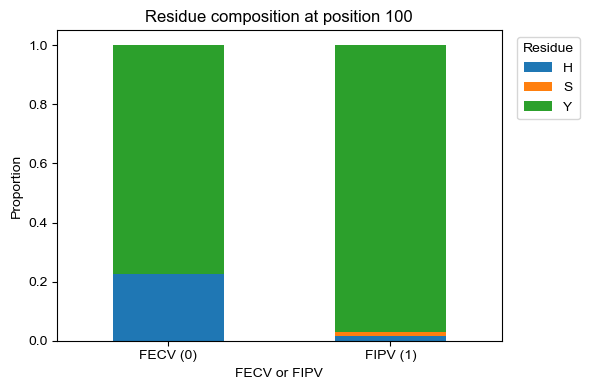

In [25]:
pos = 100  # 1-based position

df = df_selected.copy()

df["Residue"] = df["Seq"].str[pos-1]

prop = (df.groupby(["FIP_label","Residue"])
          .size()
          .groupby(level=0)
          .apply(lambda x: x / x.sum())
          .unstack(fill_value=0))

prop.plot(kind="bar", stacked=True, figsize=(6,4))
plt.ylabel("Proportion")
plt.title(f"Residue composition at position {pos}")
plt.xlabel("FECV or FIPV")
plt.xticks([0,1], ["FECV (0)", "FIPV (1)"], rotation=0)
plt.legend(title="Residue", bbox_to_anchor=(1.02,1))
plt.tight_layout()
plt.show()

### fecv consensusの多型を考慮してconsensusに選ばれなかった30%以上のfrequencyのアミノ酸をconsensusとして検定

In [31]:
# 出現頻度が30%以上の多型でも同様に検定

major_poly_highlighted = []
n_samples = len(fecv_df)
for site in polymorphic_sites:
    pos = site['position']
    variations = site['variation']
    
    # 頻度計算
    freq_dist = {amino: count / n_samples for amino, count in variations.items()}
    # 30%以上のものだけを抽出
    high_freq_vars = {amino: f"{freq:.1%}" for amino, freq in freq_dist.items() if freq >= 0.3}
    
    # 30%以上が2つ以上ある場合のみ処理
    if len(high_freq_vars) >= 2:
        # このポジションのコンセンサス文字を取得
        con_char = consensus[pos - 1]
        
        # コンセンサス文字に星印（★）をつける、または辞書内で目立たせる
        highlighted_vars = {}
        for amino, perc in high_freq_vars.items():
            if amino == con_char:
                highlighted_vars[f"★{amino}(consensus)"] = perc
            else:
                highlighted_vars[amino] = perc
                
        major_poly_highlighted.append({
            'position': pos,
            'variants_with_consensus': highlighted_vars,
            'total_variants': len(variations)
        })

# 結果を表示
df_highlighted = pd.DataFrame(major_poly_highlighted)
pd.set_option('display.max_colwidth', None)
print(df_highlighted)

   position                   variants_with_consensus  total_variants
0         9  {'★I(consensus)': '59.2%', 'V': '30.6%'}               4
1        24  {'★L(consensus)': '65.3%', 'P': '34.7%'}               2
2        50  {'★I(consensus)': '61.2%', 'V': '36.7%'}               3
3        64  {'★V(consensus)': '57.1%', 'I': '42.9%'}               2
4       149  {'★Y(consensus)': '53.1%', 'H': '38.8%'}               4
5       198  {'★I(consensus)': '65.3%', 'L': '34.7%'}               2


In [32]:
import pandas as pd
import numpy as np
from scipy.stats import fisher_exact
from statsmodels.stats.multitest import multipletests

re_test_records = []

# --- 1. 再検定ループの実行 ---
for item in major_poly_highlighted:
    pos_1based = item['position']
    pos_0indexed = pos_1based - 1
    
    # コンセンサス以外の30%以上の多型アミノ酸を基準にする
    high_freq_vars = item['variants_with_consensus']
    new_refs = [aa.replace('★', '').replace('(consensus)', '') 
                for aa in high_freq_vars.keys() if '★' not in aa]
    
    col = np.array([s[pos_0indexed] for s in seqs])
    
    for ref in new_refs:
        # 有効データのフィルタリング
        valid_mask = np.array([(aa not in INVALID_AA) and (ref not in INVALID_AA) for aa in col])
        col_valid = col[valid_mask]
        y_valid = y[valid_mask]
        if len(col_valid) < 3: continue

        # --- A) Exact AA & Any Mutation ---
        uniq = np.unique(col_valid)
        for aa in uniq:
            if aa == ref: continue
            aa_mask = (col_valid == aa)
            a, b, c, d, OR, p = fisher_from_mask(aa_mask, y_valid)
            re_test_records.append({
                "test_type": "exact_aa", "pos": pos_1based, "new_ref": ref,
                "feature": f"{ref}{pos_1based}{aa}", "p": p, "OR": OR, "a_case": a, "b_ctrl": b
            })

        any_mut_mask = (col_valid != ref)
        if np.any(any_mut_mask) and np.any(~any_mut_mask):
            a, b, c, d, OR, p = fisher_from_mask(any_mut_mask, y_valid)
            re_test_records.append({
                "test_type": "any_mutation", "pos": pos_1based, "new_ref": ref,
                "feature": f"{ref}{pos_1based}mut", "p": p, "OR": OR, "a_case": a, "b_ctrl": b
            })

        # --- B) Class Based Test ---
        ref_cls = aa_class(ref)
        col_cls = np.array([aa_class(aa) for aa in col_valid], dtype=object)
        cls_valid_mask = np.array([c is not None for c in col_cls])
        col_cls2 = col_cls[cls_valid_mask]; y_valid2 = y_valid[cls_valid_mask]

        if len(col_cls2) >= 3 and ref_cls is not None:
            # 性質変化
            class_changed_mask = (col_cls2 != ref_cls)
            if np.any(class_changed_mask) and np.any(~class_changed_mask):
                a, b, c, d, OR, p = fisher_from_mask(class_changed_mask, y_valid2)
                re_test_records.append({
                    "test_type": "class_changed", "pos": pos_1based, "new_ref": ref,
                    "feature": f"{ref}{pos_1based}class_change", "p": p, "OR": OR, "a_case": a, "b_ctrl": b
                })

            # 特定の性質への変化
            observed_classes = sorted(set([c for c in col_cls2 if c is not None]))
            for target_cls in observed_classes:
                if target_cls == ref_cls: continue
                target_class_mask = (col_cls2 == target_cls)
                if np.any(target_class_mask) and np.any(~target_class_mask):
                    a, b, c, d, OR, p = fisher_from_mask(target_class_mask, y_valid2)
                    re_test_records.append({
                        "test_type": "target_class", "pos": pos_1based, "new_ref": ref,
                        "feature": f"{ref}{pos_1based}{target_cls}", "p": p, "OR": OR, "a_case": a, "b_ctrl": b
                    })

# --- 2. P値の補正と集計 ---
if re_test_records:
    res_retest = pd.DataFrame(re_test_records)
    # 全体でのFDR補正
    res_retest["p_corrected_global"] = multipletests(res_retest["p"], method="fdr_bh")[1]

    # --- 3. ピボットテーブル化 ---
    # 各pos, new_refに対して、各検定タイプの最小P値を表示
    retest_pivot = res_retest.pivot_table(
        index=["pos", "new_ref"], 
        columns="test_type", 
        values="p_corrected_global",
        aggfunc='min'
    )

    # --- 4. スタイリング（小数点表示とハイライト） ---
    styled_retest = retest_pivot.style.format("{:.10f}", na_rep="-").applymap(
        lambda val: 'background-color: #ffffb3; font-weight: bold;' if (not pd.isna(val) and val < 0.1) else ''
    )
    
    # 表示
    display(styled_retest)

/var/folders/f6/6b_f_s9n3d76xj2klrny2lpm0000gn/T/ipykernel_14504/1826931545.py:90: FutureWarning: Styler.applymap has been deprecated. Use Styler.map instead.
  styled_retest = retest_pivot.style.format("{:.10f}", na_rep="-").applymap(


,test_type,any_mutation,class_changed,exact_aa,target_class
pos,new_ref,,,,
9,V,1.0000000000,0.9092650849,0.7250769527,0.7250769527
24,P,0.9740157433,0.9740157433,0.9740157433,0.9740157433
50,V,0.9740157433,1.0000000000,0.9265550296,1.0000000000
64,I,0.8194982838,-,0.8598486182,-
149,H,0.7250769527,0.7250769527,0.7250769527,0.7250769527
198,L,0.8598486182,0.7250769527,0.8598486182,0.8598486182
